In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("FoodWaste AI Project Started!")

FoodWaste AI Project Started!


In [2]:
train = pd.read_csv('/content/train.csv')
test = pd.read_csv('/content/test.csv')
submission = pd.read_csv('/content/submission.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print("Submission Shape:", submission.shape)

Train Shape: (911, 12)
Test Shape: (911, 11)
Submission Shape: (911, 2)


In [4]:
print("First 5 rows",train.head)

First 5 rows <bound method NDFrame.head of        ID        date  meals_served  kitchen_staff  temperature_C  \
0       0  2022-12-19           196             13      27.887273   
1       1  2023-11-21           244             15      10.317872   
2       4  2022-02-01           148             16      27.714300   
3       5  2023-03-19           157             19      19.173902   
4       6  2022-07-18           297             10      26.375233   
..    ...         ...           ...            ...            ...   
906  1044  2022-03-29           395             18      17.354199   
907  1045  2022-11-27           483             11      24.912137   
908  1046  2023-04-12           243             11      28.870945   
909  1048  2022-02-14           406             10      19.061638   
910  1049  2024-05-10           350              6      23.708015   

     humidity_percent  day_of_week  special_event  past_waste_kg  \
0           45.362854            0              0       7.74

In [5]:
print(train.head(10))

   ID        date  meals_served  kitchen_staff  temperature_C  \
0   0  2022-12-19           196             13      27.887273   
1   1  2023-11-21           244             15      10.317872   
2   4  2022-02-01           148             16      27.714300   
3   5  2023-03-19           157             19      19.173902   
4   6  2022-07-18           297             10      26.375233   
5   7  2023-03-02           241             18      16.863506   
6   8  2022-04-18           443             16      19.888627   
7   9  2023-12-16           416             16      18.559591   
8  10  2023-07-07           439             18      24.111027   
9  11  2023-11-07           267              7      25.412493   

   humidity_percent  day_of_week  special_event  past_waste_kg  \
0         45.362854            0              0       7.740587   
1         64.430475            1              0      42.311779   
2         69.046113            1              0      41.184305   
3         46.292823 

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                911 non-null    int64  
 1   date              911 non-null    object 
 2   meals_served      911 non-null    int64  
 3   kitchen_staff     911 non-null    int64  
 4   temperature_C     911 non-null    float64
 5   humidity_percent  911 non-null    float64
 6   day_of_week       911 non-null    int64  
 7   special_event     911 non-null    int64  
 8   past_waste_kg     911 non-null    float64
 9   staff_experience  747 non-null    object 
 10  waste_category    911 non-null    object 
 11  food_waste_kg     911 non-null    float64
dtypes: float64(4), int64(5), object(3)
memory usage: 85.5+ KB


In [7]:
print(train.describe())

                ID  meals_served  kitchen_staff  temperature_C  \
count   911.000000    911.000000     911.000000     911.000000   
mean    528.327113    375.405049      11.900110      22.189280   
std     305.072794    502.812717       4.285153       8.922389   
min       0.000000    100.000000       5.000000     -10.372207   
25%     266.000000    211.000000       8.000000      15.684585   
50%     531.000000    306.000000      12.000000      22.115040   
75%     795.500000    407.000000      15.000000      28.804294   
max    1049.000000   4730.000000      19.000000      60.000000   

       humidity_percent  day_of_week  special_event  past_waste_kg  \
count        911.000000   911.000000     911.000000     911.000000   
mean          60.761313     3.014270       0.085620      27.015691   
std           17.330821     2.009542       0.279956      12.774223   
min           30.121111     0.000000       0.000000       5.008394   
25%           46.017835     1.000000       0.000000    

In [8]:
print(train.isnull().sum())

ID                    0
date                  0
meals_served          0
kitchen_staff         0
temperature_C         0
humidity_percent      0
day_of_week           0
special_event         0
past_waste_kg         0
staff_experience    164
waste_category        0
food_waste_kg         0
dtype: int64


In [9]:
print("Duplicate Rows:", train.duplicated().sum())

Duplicate Rows: 0


In [10]:
print(train.columns.tolist())

['ID', 'date', 'meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'staff_experience', 'waste_category', 'food_waste_kg']


In [11]:
print("Staff Experience Values:")
print(train['staff_experience'].value_counts(dropna=False))

print("\nWaste Category Values:")
print(train['waste_category'].value_counts(dropna=False))

Staff Experience Values:
staff_experience
Beginner        191
EXPERT          186
Intermediate    186
intermediate    184
NaN             164
Name: count, dtype: int64

Waste Category Values:
waste_category
MEAT          210
dairy         180
Vegetables    176
GRAINS        176
MeAt          169
Name: count, dtype: int64


In [12]:
for col in train.columns:
    print(col)

ID
date
meals_served
kitchen_staff
temperature_C
humidity_percent
day_of_week
special_event
past_waste_kg
staff_experience
waste_category
food_waste_kg


In [13]:
# Create copies of original datasets
clean_train = train.copy()
clean_test = test.copy()

# Standardize categorical text
for df in [clean_train, clean_test]:

    for col in ['staff_experience', 'waste_category']:

        if col in df.columns:
            df[col] = df[col].str.strip().str.lower()

print("Categorical data standardized!")

Categorical data standardized!


In [14]:
print(clean_train['staff_experience'].value_counts(dropna=False))

print("\nWaste Category:")
print(clean_train['waste_category'].value_counts(dropna=False))

staff_experience
intermediate    370
beginner        191
expert          186
NaN             164
Name: count, dtype: int64

Waste Category:
waste_category
meat          379
dairy         180
vegetables    176
grains        176
Name: count, dtype: int64


In [15]:
for df in [clean_train, clean_test]:

    if 'staff_experience' in df.columns:
        df['staff_experience'] = (
            df['staff_experience'].fillna('unknown')
        )

print("Missing values handled!")

Missing values handled!


In [16]:
print(clean_train['staff_experience'].isnull().sum())

print(clean_train['staff_experience'].value_counts())

0
staff_experience
intermediate    370
beginner        191
expert          186
unknown         164
Name: count, dtype: int64


In [17]:
for df in [clean_train, clean_test]:

    df['date'] = pd.to_datetime(df['date'])

print(clean_train['date'].dtype)

datetime64[ns]


In [18]:
for df in [clean_train, clean_test]:

    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day

print(clean_train[['date', 'year', 'month', 'day']].head())

        date  year  month  day
0 2022-12-19  2022     12   19
1 2023-11-21  2023     11   21
2 2022-02-01  2022      2    1
3 2023-03-19  2023      3   19
4 2022-07-18  2022      7   18


In [19]:
print(clean_train['food_waste_kg'].describe())

count    911.000000
mean      44.842691
std       27.934366
min       10.819048
25%       32.887912
50%       41.146930
75%       50.046681
max      274.328783
Name: food_waste_kg, dtype: float64


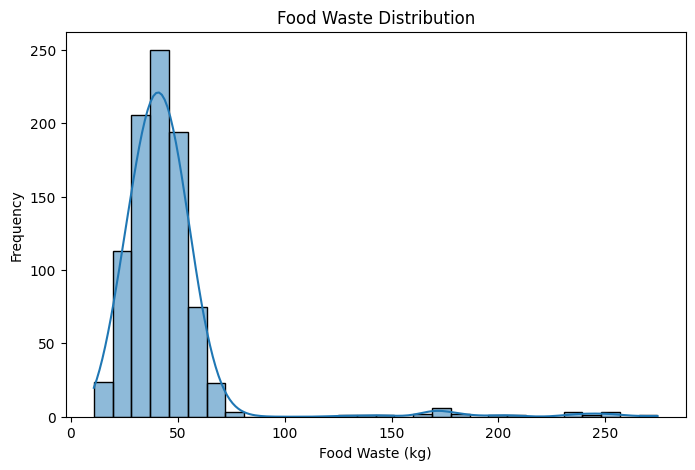

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    clean_train['food_waste_kg'],
    bins=30,
    kde=True
)

plt.title('Food Waste Distribution')
plt.xlabel('Food Waste (kg)')
plt.ylabel('Frequency')

plt.show()

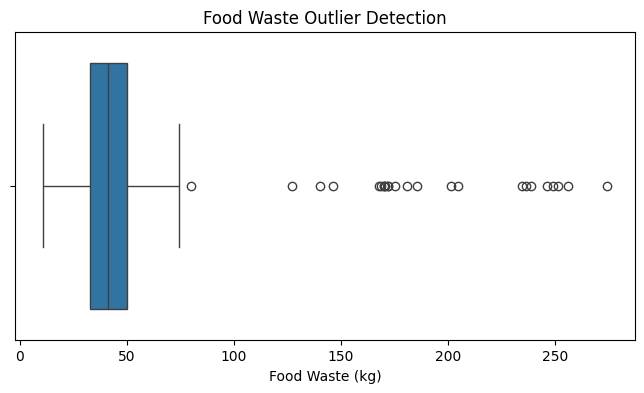

In [21]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=clean_train['food_waste_kg'])

plt.title('Food Waste Outlier Detection')
plt.xlabel('Food Waste (kg)')

plt.show()

In [22]:
Q1 = clean_train['food_waste_kg'].quantile(0.25)

Q3 = clean_train['food_waste_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 32.88791193679356
Q3: 50.04668103305428
IQR: 17.15876909626072
Lower Limit: 7.149758292402478
Upper Limit: 75.78483467744536


In [23]:
outliers = clean_train[
    (clean_train['food_waste_kg'] < lower_limit) |
    (clean_train['food_waste_kg'] > upper_limit)
]

print("Total Outliers:", len(outliers))

Total Outliers: 24


In [24]:
print(
    outliers[
        ['ID', 'date', 'meals_served',
         'past_waste_kg', 'waste_category',
         'food_waste_kg']
    ].sort_values(
        by='food_waste_kg',
        ascending=False
    )
)

      ID       date  meals_served  past_waste_kg waste_category  food_waste_kg
321  375 2022-08-17          3190      46.289435           meat     274.328783
448  524 2023-01-11          4010      31.732226           meat     256.325524
368  432 2023-12-24          4680      26.208872           meat     251.538932
409  481 2023-10-30          1750      36.542091           meat     249.173878
129  147 2022-11-16          2930      20.743447           meat     246.359169
176  208 2023-09-15          3160      24.266983           meat     238.887756
687  800 2024-01-06          4730      14.096723     vegetables     236.740804
213  249 2022-08-04          1510      47.858689         grains     234.785567
608  707 2024-06-14          2830      27.800861           meat     205.023051
21    24 2023-07-25          1110      38.878190     vegetables     201.327227
642  748 2024-09-19          3380      26.434506          dairy     185.694333
284  331 2022-07-16          3580      23.680622    

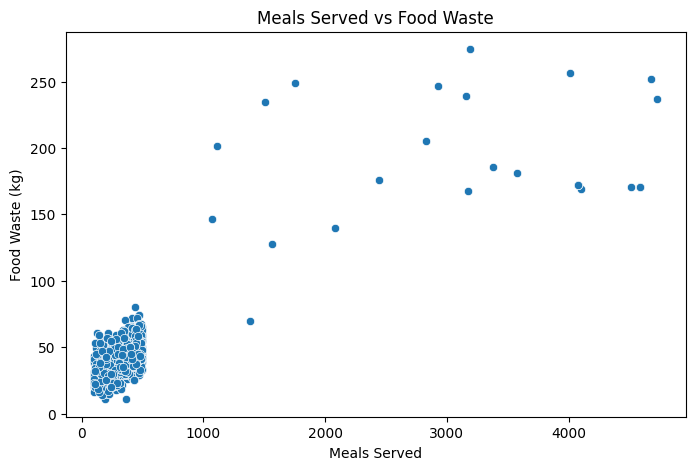

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_train,
    x='meals_served',
    y='food_waste_kg'
)

plt.title('Meals Served vs Food Waste')
plt.xlabel('Meals Served')
plt.ylabel('Food Waste (kg)')

plt.show()

In [26]:
correlation = clean_train[
    ['meals_served', 'food_waste_kg']
].corr()

print(correlation)

               meals_served  food_waste_kg
meals_served       1.000000       0.852128
food_waste_kg      0.852128       1.000000


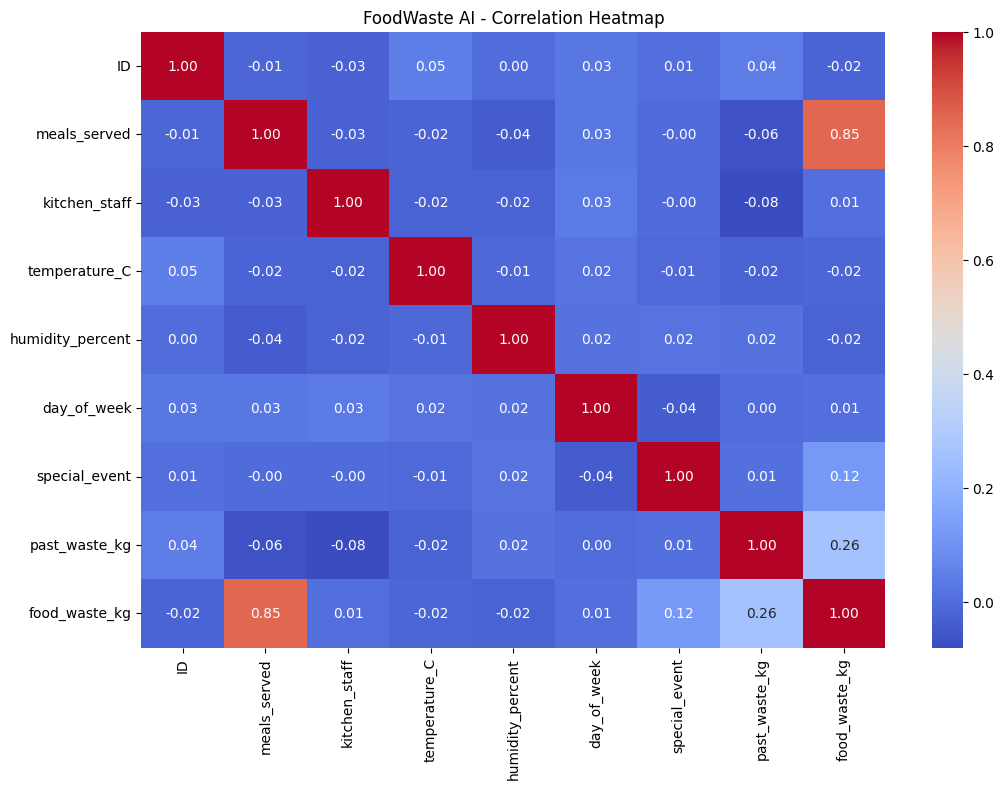

In [27]:
plt.figure(figsize=(12, 8))

numeric_data = clean_train.select_dtypes(
    include=['int64', 'float64']
)

correlation_matrix = numeric_data.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('FoodWaste AI - Correlation Heatmap')

plt.show()

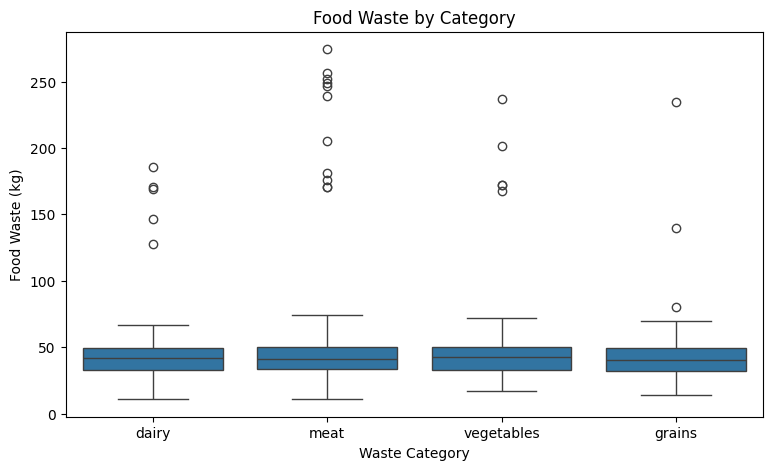

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clean_train,
    x='waste_category',
    y='food_waste_kg'
)

plt.title('Food Waste by Category')
plt.xlabel('Waste Category')
plt.ylabel('Food Waste (kg)')

plt.show()

In [29]:
category_analysis = clean_train.groupby(
    'waste_category'
)['food_waste_kg'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

print(category_analysis)

                     mean     median        min         max  count
waste_category                                                    
dairy           43.555220  41.510718  10.819048  185.694333    180
grains          42.000976  40.320013  13.960702  234.785567    176
meat            46.304579  41.259082  11.181282  274.328783    379
vegetables      45.853093  42.604379  17.158902  236.740804    176


In [30]:
for df in [clean_train, clean_test]:

    df['is_weekend'] = (
        df['date'].dt.dayofweek >= 5
    ).astype(int)

print(clean_train[
    ['date', 'day_of_week', 'is_weekend']
].head(10))

        date  day_of_week  is_weekend
0 2022-12-19            0           0
1 2023-11-21            1           0
2 2022-02-01            1           0
3 2023-03-19            6           1
4 2022-07-18            0           0
5 2023-03-02            3           0
6 2022-04-18            0           0
7 2023-12-16            5           1
8 2023-07-07            4           0
9 2023-11-07            1           0


In [31]:
print("Staff Experience:")
print(clean_train['staff_experience'].unique())

print("\nWaste Category:")
print(clean_train['waste_category'].unique())

Staff Experience:
['intermediate' 'unknown' 'beginner' 'expert']

Waste Category:
['dairy' 'meat' 'vegetables' 'grains']


In [32]:
sample = pd.DataFrame({
    'waste_category': ['dairy', 'meat', 'grains', 'vegetables']
})

encoded_sample = pd.get_dummies(
    sample,
    columns=['waste_category'],
    dtype=int
)

print(encoded_sample)

   waste_category_dairy  waste_category_grains  waste_category_meat  \
0                     1                      0                    0   
1                     0                      0                    1   
2                     0                      1                    0   
3                     0                      0                    0   

   waste_category_vegetables  
0                          0  
1                          0  
2                          0  
3                          1  


In [33]:
sample_staff = pd.DataFrame({
    'staff_experience': [
        'beginner',
        'intermediate',
        'expert',
        'unknown'
    ]
})

encoded_staff = pd.get_dummies(
    sample_staff,
    columns=['staff_experience'],
    dtype=int
)

print(encoded_staff)

   staff_experience_beginner  staff_experience_expert  \
0                          1                        0   
1                          0                        0   
2                          0                        1   
3                          0                        0   

   staff_experience_intermediate  staff_experience_unknown  
0                              0                         0  
1                              1                         0  
2                              0                         0  
3                              0                         1  


In [34]:
train_size = len(clean_train)

combined = pd.concat(
    [clean_train, clean_test],
    ignore_index=True
)

combined = pd.get_dummies(
    combined,
    columns=['staff_experience', 'waste_category'],
    dtype=int
)

encoded_train = combined.iloc[:train_size].copy()
encoded_test = combined.iloc[train_size:].copy()

print("Train shape:", encoded_train.shape)
print("Test shape:", encoded_test.shape)

print(encoded_train.head())

Train shape: (911, 22)
Test shape: (911, 22)
   ID       date  meals_served  kitchen_staff  temperature_C  \
0   0 2022-12-19           196             13      27.887273   
1   1 2023-11-21           244             15      10.317872   
2   4 2022-02-01           148             16      27.714300   
3   5 2023-03-19           157             19      19.173902   
4   6 2022-07-18           297             10      26.375233   

   humidity_percent  day_of_week  special_event  past_waste_kg  food_waste_kg  \
0         45.362854            0              0       7.740587      28.946465   
1         64.430475            1              0      42.311779      51.549053   
2         69.046113            1              0      41.184305      53.008323   
3         46.292823            6              0      41.543492      48.621527   
4         79.741064            0              0      26.525097      44.156984   

   ...  day  is_weekend  staff_experience_beginner  staff_experience_expert  \
0  .

In [35]:
X = encoded_train.drop(
    columns=['ID', 'date', 'food_waste_kg']
)

y = encoded_train['food_waste_kg']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

X Shape: (911, 19)
y Shape: (911,)

Input Features:
['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'year', 'month', 'day', 'is_weekend', 'staff_experience_beginner', 'staff_experience_expert', 'staff_experience_intermediate', 'staff_experience_unknown', 'waste_category_dairy', 'waste_category_grains', 'waste_category_meat', 'waste_category_vegetables']


In [36]:
# Sort records by date
sorted_data = encoded_train.sort_values(
    by='date'
).copy()

# Separate inputs and target
X = sorted_data.drop(
    columns=['ID', 'date', 'food_waste_kg']
)

y = sorted_data['food_waste_kg']

# 80% training, 20% testing
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (728, 19)
X_test: (183, 19)
y_train: (728,)
y_test: (183,)


In [37]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [38]:
# Predict food waste
y_pred = lr_model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[30.25087654 47.09772643 40.62244912 27.96939657 35.16481028 33.25281357
 47.20295778 37.80635411 31.82761608 29.67590591]

Predicted Values:
[32.9182387  49.46536906 43.3449146  28.56143453 36.66941607 43.83929455
 53.01000619 43.98875274 39.04694106 38.00022539]


In [39]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 5.066652863634376


In [40]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 7.449094955316979


In [41]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.91472182293527


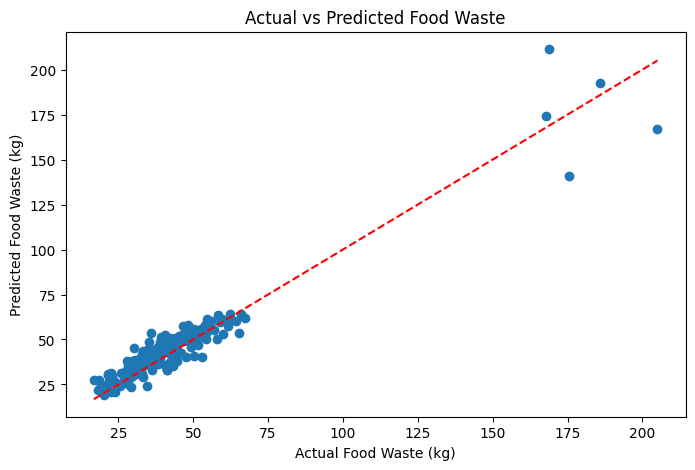

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Food Waste (kg)")
plt.ylabel("Predicted Food Waste (kg)")
plt.title("Actual vs Predicted Food Waste")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [43]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 5.324372939327759
Random Forest RMSE: 8.430631113925493
Random Forest R2 Score: 0.8907677042524259


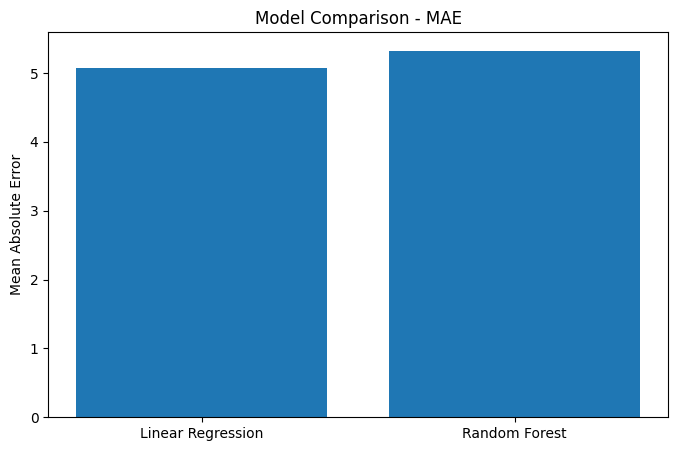

In [45]:
models = ['Linear Regression', 'Random Forest']

mae_scores = [mae, rf_mae]
rmse_scores = [rmse, rf_rmse]
r2_scores = [r2, rf_r2]

plt.figure(figsize=(8, 5))

plt.bar(models, mae_scores)

plt.title('Model Comparison - MAE')
plt.ylabel('Mean Absolute Error')

plt.show()

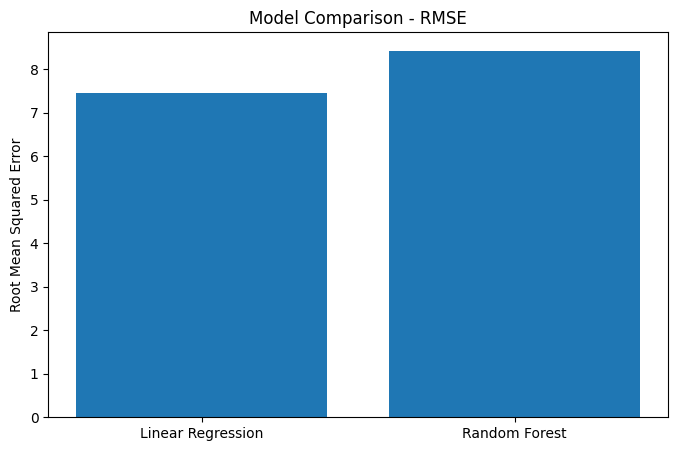

In [46]:
plt.figure(figsize=(8, 5))

plt.bar(models, rmse_scores)

plt.title('Model Comparison - RMSE')
plt.ylabel('Root Mean Squared Error')

plt.show()

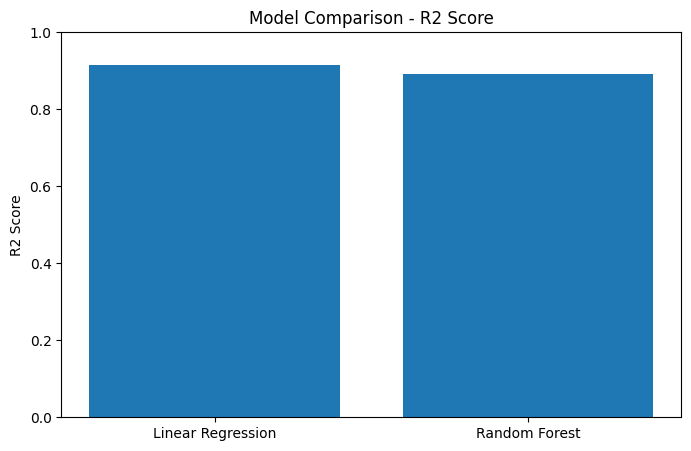

In [47]:
plt.figure(figsize=(8, 5))

plt.bar(models, r2_scores)

plt.title('Model Comparison - R2 Score')
plt.ylabel('R2 Score')

plt.ylim(0, 1)

plt.show()

In [48]:
print([name for name in globals() if 'model' in name.lower()])

['lr_model', 'rf_model', 'models']


In [49]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    lr_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("Cross Validation Scores:", cv_scores)
print("Average CV Score:", cv_scores.mean())

Cross Validation Scores: [0.66886916 0.80560884 0.79902341 0.83721485 0.91474136]
Average CV Score: 0.8050915217425215


In [50]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
})

importance['Absolute_Importance'] = (
    importance['Coefficient'].abs()
)

importance = importance.sort_values(
    by='Absolute_Importance',
    ascending=False
)

print(importance)

                          Feature  Coefficient  Absolute_Importance
5                   special_event    11.019146            11.019146
10                     is_weekend    -1.123266             1.123266
7                            year     0.774970             0.774970
6                   past_waste_kg     0.708633             0.708633
15           waste_category_dairy    -0.591174             0.591174
12        staff_experience_expert     0.556945             0.556945
17            waste_category_meat     0.487368             0.487368
16          waste_category_grains     0.422093             0.422093
1                   kitchen_staff     0.404396             0.404396
11      staff_experience_beginner    -0.367613             0.367613
13  staff_experience_intermediate    -0.328795             0.328795
18      waste_category_vegetables    -0.318287             0.318287
8                           month     0.231856             0.231856
14       staff_experience_unknown     0.139463  

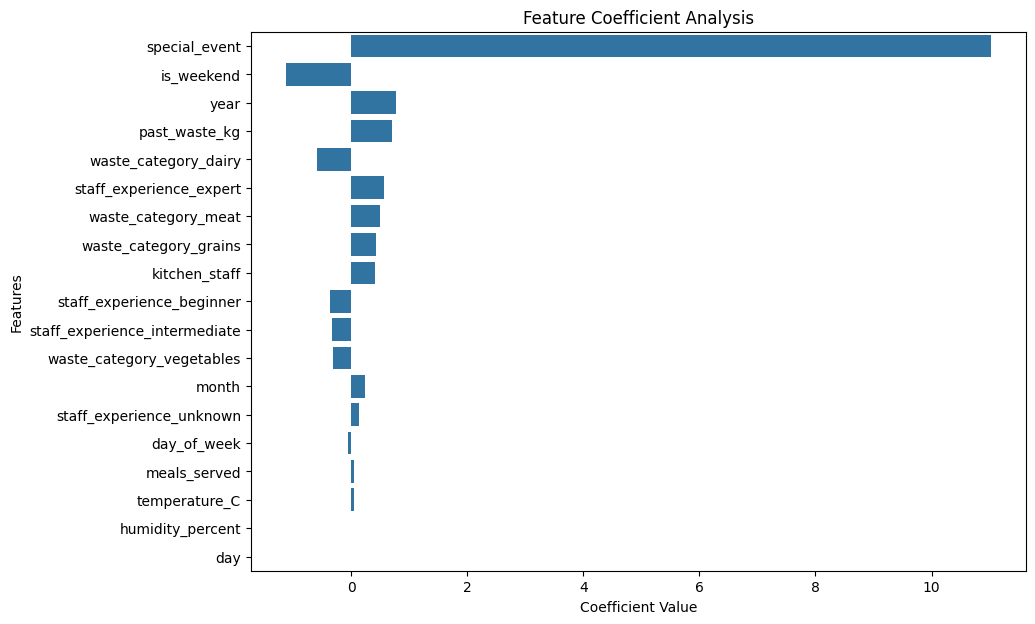

In [51]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance,
    x='Coefficient',
    y='Feature'
)

plt.title('Feature Coefficient Analysis')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')

plt.show()

In [52]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)


Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best CV Score: 0.8858193760422836


In [53]:

best_rf_model = grid_search.best_estimator_

rf_pred = best_rf_model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Tuned Random Forest MAE:", rf_mae)
print("Tuned Random Forest RMSE:", rf_rmse)
print("Tuned Random Forest R2 Score:", rf_r2)


Tuned Random Forest MAE: 5.375813690572034
Tuned Random Forest RMSE: 8.677290370754157
Tuned Random Forest R2 Score: 0.884282471691585


In [54]:

import joblib

joblib.dump(lr_model, 'food_waste_model.pkl')

print("Best Model Saved Successfully!")


Best Model Saved Successfully!


In [55]:
loaded_model = joblib.load('food_waste_model.pkl')

test_predictions = loaded_model.predict(X_test)

print("Model Loaded Successfully!")
print("First 10 Predictions:")
print(test_predictions[:10])

Model Loaded Successfully!
First 10 Predictions:
[32.9182387  49.46536906 43.3449146  28.56143453 36.66941607 43.83929455
 53.01000619 43.98875274 39.04694106 38.00022539]


In [56]:
# Check test dataset columns
print(encoded_test.shape)
print(encoded_test.columns.tolist())

(911, 22)
['ID', 'date', 'meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'food_waste_kg', 'year', 'month', 'day', 'is_weekend', 'staff_experience_beginner', 'staff_experience_expert', 'staff_experience_intermediate', 'staff_experience_unknown', 'waste_category_dairy', 'waste_category_grains', 'waste_category_meat', 'waste_category_vegetables']


In [57]:
X_kaggle = encoded_test.drop(
    columns=['ID', 'date', 'food_waste_kg'],
    errors='ignore'
)

# Match training feature order
X_kaggle = X_kaggle[X_train.columns]

print("Kaggle Test Shape:", X_kaggle.shape)

Kaggle Test Shape: (911, 19)


In [58]:
kaggle_predictions = loaded_model.predict(X_kaggle)

print("Predictions generated!")
print(kaggle_predictions[:10])

Predictions generated!
[23.00668302 51.83591642 44.13074269 45.39210492 39.6768491  28.00945186
 44.81659531 64.86963891 43.89415526 36.94098644]


In [59]:
print(submission.head())
print(submission.columns)
print(submission.shape)

   ID  food_waste_kg
0   0      28.946465
1   1      51.549053
2   4      53.008323
3   5      48.621527
4   6      44.156984
Index(['ID', 'food_waste_kg'], dtype='object')
(911, 2)


In [60]:
# Create prediction dataframe using original test IDs
prediction_df = pd.DataFrame({
    'ID': encoded_test['ID'],
    'food_waste_kg': kaggle_predictions
})

# Update submission while preserving its original ID order
submission = submission.drop(columns=['food_waste_kg']).merge(
    prediction_df,
    on='ID',
    how='left',
    sort=False
)

print(submission.head(10))
print("\nSubmission Shape:", submission.shape)
print("Missing Predictions:", submission['food_waste_kg'].isnull().sum())

   ID  food_waste_kg
0   0      23.006683
1   1      51.835916
2   4      44.130743
3   5      45.392105
4   6      39.676849
5   7      28.009452
6   8      44.816595
7   9      64.869639
8  10      43.894155
9  11      36.940986

Submission Shape: (911, 2)
Missing Predictions: 0


In [61]:
submission.to_csv('food_waste_submission.csv', index=False)

from google.colab import files
files.download('food_waste_submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [63]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Results")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Results
MAE: 7.646870868085506
RMSE: 13.186222013107457
R2 Score: 0.7327783418143764


           Algorithm       MAE       RMSE  R2 Score
0  Linear Regression  5.067000   7.449000  0.914700
1      Random Forest  5.324000   8.431000  0.890800
2      Decision Tree  7.646871  13.186222  0.732778


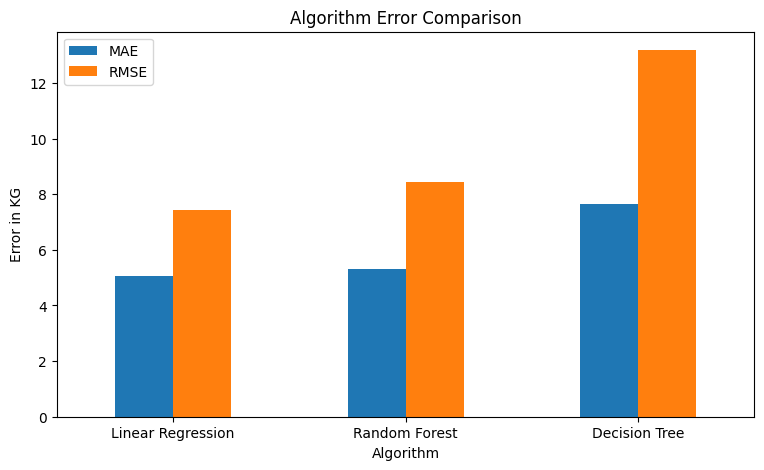

In [64]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Algorithm': ['Linear Regression', 'Random Forest', 'Decision Tree'],
    'MAE': [5.067, 5.324, dt_mae],
    'RMSE': [7.449, 8.431, dt_rmse],
    'R2 Score': [0.9147, 0.8908, dt_r2]
})

print(comparison)

comparison.plot(
    x='Algorithm',
    y=['MAE', 'RMSE'],
    kind='bar',
    figsize=(9, 5)
)

plt.title('Algorithm Error Comparison')
plt.ylabel('Error in KG')
plt.xticks(rotation=0)
plt.show()

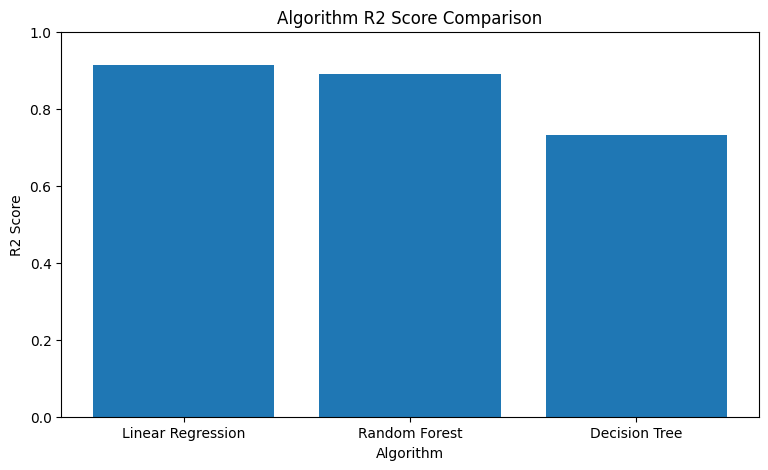

In [65]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison['Algorithm'],
    comparison['R2 Score']
)

plt.title('Algorithm R2 Score Comparison')
plt.xlabel('Algorithm')
plt.ylabel('R2 Score')
plt.ylim(0, 1)

plt.show()

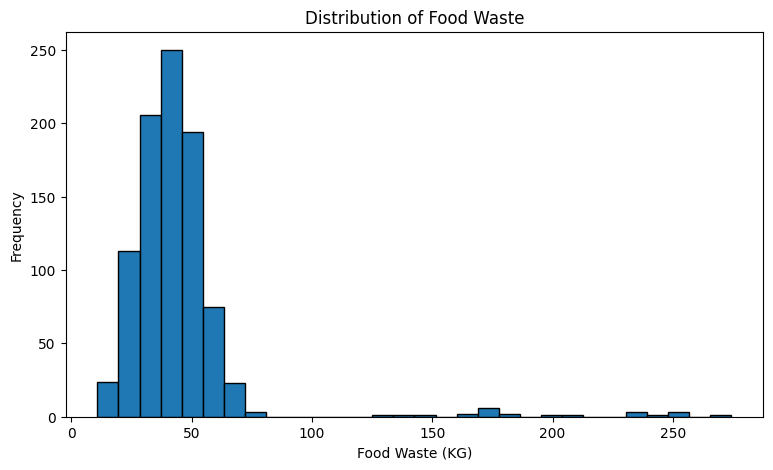

In [66]:
plt.figure(figsize=(9, 5))

plt.hist(
    clean_train['food_waste_kg'],
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Food Waste')
plt.xlabel('Food Waste (KG)')
plt.ylabel('Frequency')

plt.show()

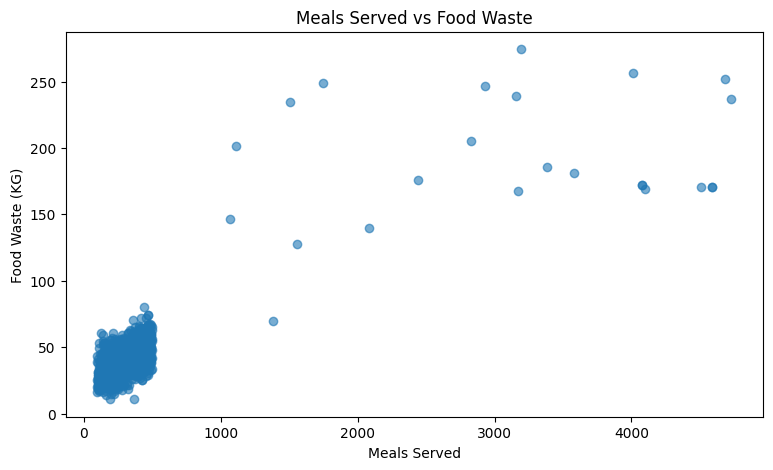

In [67]:
plt.figure(figsize=(9, 5))

plt.scatter(
    clean_train['meals_served'],
    clean_train['food_waste_kg'],
    alpha=0.6
)

plt.title('Meals Served vs Food Waste')
plt.xlabel('Meals Served')
plt.ylabel('Food Waste (KG)')
plt.show()

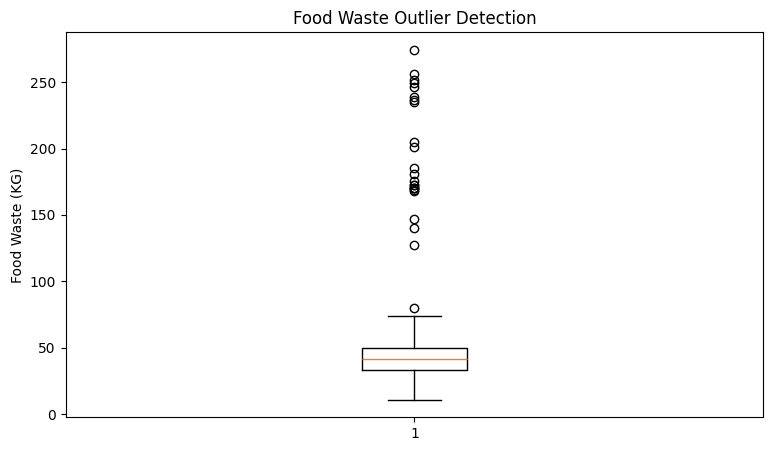

In [68]:
plt.figure(figsize=(9, 5))

plt.boxplot(clean_train['food_waste_kg'])

plt.title('Food Waste Outlier Detection')
plt.ylabel('Food Waste (KG)')

plt.show()

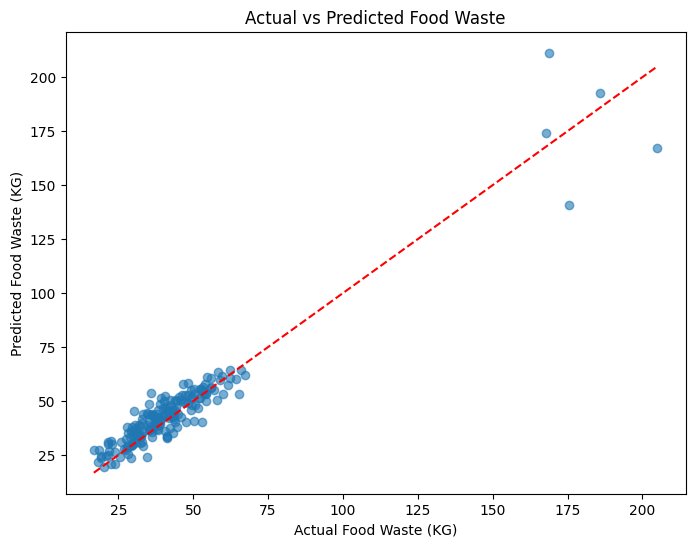

In [69]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted Food Waste')
plt.xlabel('Actual Food Waste (KG)')
plt.ylabel('Predicted Food Waste (KG)')

plt.show()

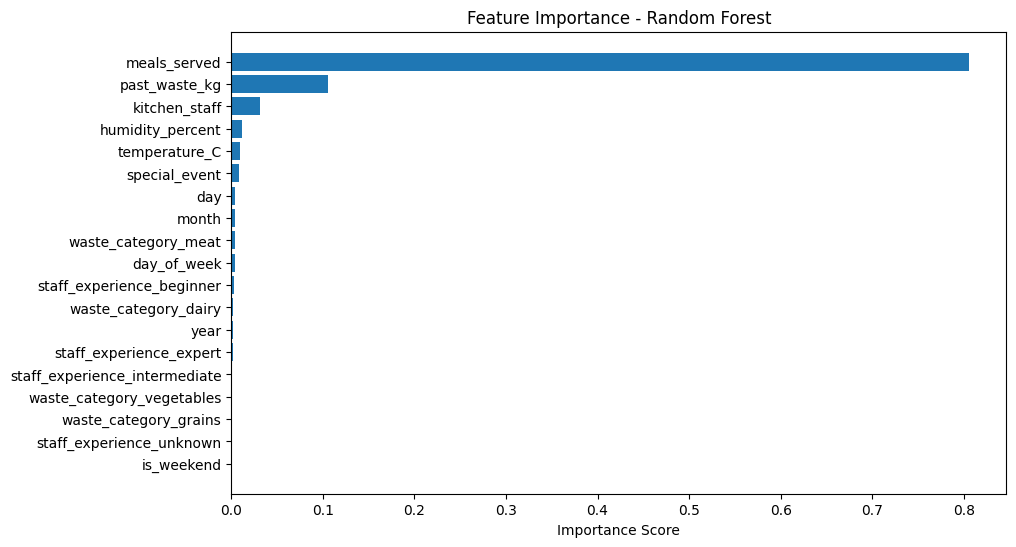

In [70]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()

plt.show()

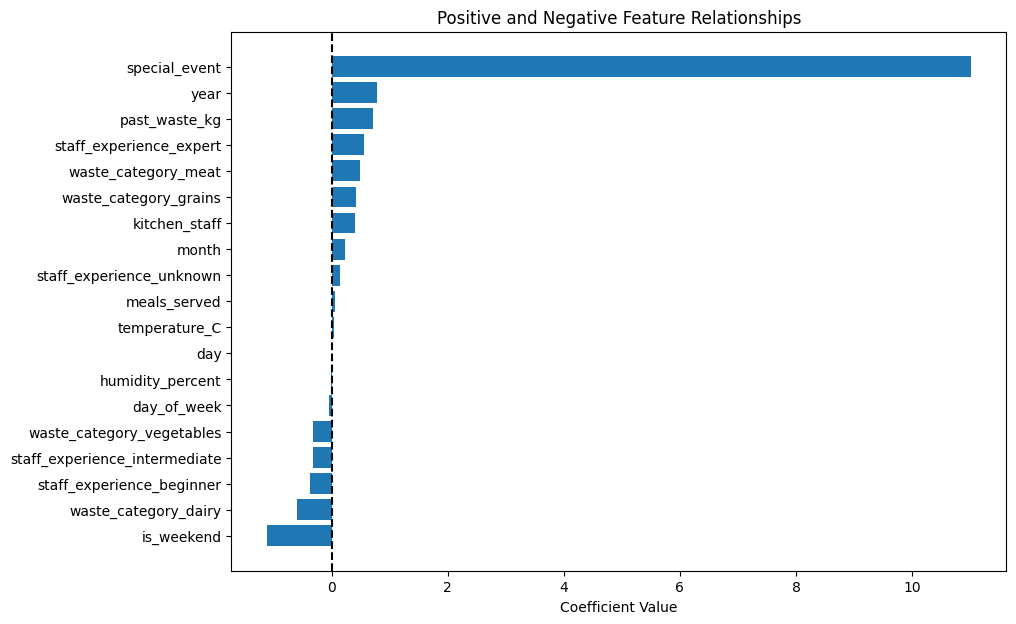

In [71]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_
})

coefficients = coefficients.sort_values(
    by='Coefficient'
)

plt.figure(figsize=(10, 7))

plt.barh(
    coefficients['Feature'],
    coefficients['Coefficient']
)

plt.axvline(x=0, color='black', linestyle='--')

plt.title('Positive and Negative Feature Relationships')
plt.xlabel('Coefficient Value')

plt.show()

In [72]:
print("Dataset Shape:", clean_train.shape)

print("\nDataset Columns:")
print(clean_train.columns.tolist())

print("\nData Types:")
print(clean_train.dtypes)

print("\nMissing Values:")
print(clean_train.isnull().sum())

Dataset Shape: (911, 16)

Dataset Columns:
['ID', 'date', 'meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'staff_experience', 'waste_category', 'food_waste_kg', 'year', 'month', 'day', 'is_weekend']

Data Types:
ID                           int64
date                datetime64[ns]
meals_served                 int64
kitchen_staff                int64
temperature_C              float64
humidity_percent           float64
day_of_week                  int64
special_event                int64
past_waste_kg              float64
staff_experience            object
waste_category              object
food_waste_kg              float64
year                         int32
month                        int32
day                          int32
is_weekend                   int64
dtype: object

Missing Values:
ID                  0
date                0
meals_served        0
kitchen_staff       0
temperature_C       0
humidity_percent

In [73]:
# Define target
target = 'food_waste_kg'

# Columns that should not be used as model features
drop_columns = ['ID', 'date', target]

# Separate features and target
X_pipeline = clean_train.drop(columns=drop_columns)
y_pipeline = clean_train[target]

# Identify numerical and categorical columns
numeric_features = X_pipeline.select_dtypes(
    include=['int64', 'int32', 'float64']
).columns.tolist()

categorical_features = X_pipeline.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nX Shape:", X_pipeline.shape)
print("Y Shape:", y_pipeline.shape)

Numerical Features:
['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'year', 'month', 'day', 'is_weekend']

Categorical Features:
['staff_experience', 'waste_category']

X Shape: (911, 13)
Y Shape: (911,)


In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [75]:
from sklearn.model_selection import TimeSeriesSplit

# Sort dataset chronologically
sorted_pipeline_data = clean_train.sort_values(
    by='date'
).reset_index(drop=True)

# Separate X and y again after sorting
X_time = sorted_pipeline_data.drop(
    columns=['ID', 'date', 'food_waste_kg']
)

y_time = sorted_pipeline_data['food_waste_kg']

# Create TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

print("Time Series Split Created Successfully!")

print("Total Splits:", tscv.get_n_splits())
print("Dataset Shape:", X_time.shape)

Time Series Split Created Successfully!
Total Splits: 5
Dataset Shape: (911, 13)


In [76]:
for fold, (train_index, test_index) in enumerate(tscv.split(X_time)):
    print(f"\nFold {fold + 1}")
    print("Training Records:", len(train_index))
    print("Testing Records:", len(test_index))

    print(
        "Training Date Range:",
        sorted_pipeline_data.iloc[train_index]['date'].min(),
        "to",
        sorted_pipeline_data.iloc[train_index]['date'].max()
    )

    print(
        "Testing Date Range:",
        sorted_pipeline_data.iloc[test_index]['date'].min(),
        "to",
        sorted_pipeline_data.iloc[test_index]['date'].max()
    )


Fold 1
Training Records: 156
Testing Records: 151
Training Date Range: 2022-01-01 00:00:00 to 2022-05-07 00:00:00
Testing Date Range: 2022-05-08 00:00:00 to 2022-10-31 00:00:00

Fold 2
Training Records: 307
Testing Records: 151
Training Date Range: 2022-01-01 00:00:00 to 2022-10-31 00:00:00
Testing Date Range: 2022-11-01 00:00:00 to 2023-04-26 00:00:00

Fold 3
Training Records: 458
Testing Records: 151
Training Date Range: 2022-01-01 00:00:00 to 2023-04-26 00:00:00
Testing Date Range: 2023-04-27 00:00:00 to 2023-10-14 00:00:00

Fold 4
Training Records: 609
Testing Records: 151
Training Date Range: 2022-01-01 00:00:00 to 2023-10-14 00:00:00
Testing Date Range: 2023-10-15 00:00:00 to 2024-04-05 00:00:00

Fold 5
Training Records: 760
Testing Records: 151
Training Date Range: 2022-01-01 00:00:00 to 2024-04-05 00:00:00
Testing Date Range: 2024-04-06 00:00:00 to 2024-09-26 00:00:00


In [77]:
from sklearn.linear_model import LinearRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

print("Complete ML Pipeline Created Successfully!")

Complete ML Pipeline Created Successfully!


In [78]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    lr_pipeline,
    X_time,
    y_time,
    cv=tscv,
    scoring='r2',
    n_jobs=-1
)

print("Time Series Cross Validation R2 Scores:")
print(cv_scores)

print("\nAverage R2 Score:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Time Series Cross Validation R2 Scores:
[0.72436084 0.85115351 0.72918981 0.83046216 0.92793476]

Average R2 Score: 0.8126202178646199
Standard Deviation: 0.07726699820763162


In [79]:
# Train final pipeline on complete training dataset
lr_pipeline.fit(X_time, y_time)

print("Final Linear Regression Pipeline Trained Successfully!")

Final Linear Regression Pipeline Trained Successfully!


In [80]:
import joblib

joblib.dump(
    lr_pipeline,
    'foodwaste_final_pipeline.pkl'
)

print("Final Pipeline Saved Successfully!")

Final Pipeline Saved Successfully!


In [81]:
# Prepare original test features
X_test_original = sorted_pipeline_data.iloc[
    int(len(sorted_pipeline_data) * 0.8):
].drop(
    columns=['ID', 'date', 'food_waste_kg']
)

print("Test Data Shape:", X_test_original.shape)
print("Columns:")
print(X_test_original.columns.tolist())

Test Data Shape: (183, 13)
Columns:
['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'staff_experience', 'waste_category', 'year', 'month', 'day', 'is_weekend']


In [82]:
import joblib

final_model = joblib.load("/content/foodwaste_final_pipeline.pkl")

print("Final Model Loaded Successfully!")
print(type(final_model))

Final Model Loaded Successfully!
<class 'sklearn.pipeline.Pipeline'>


In [83]:
# Generate predictions using saved pipeline
final_predictions = final_model.predict(X_test_original)

print("Final Model Loaded Successfully!")
print("First 10 Predictions:")
print(final_predictions[:10])

print("\nTotal Predictions:", len(final_predictions))

Final Model Loaded Successfully!
First 10 Predictions:
[32.69434517 48.39490209 41.79116425 27.56916342 34.83755572 42.4125407
 52.27110233 42.51837366 37.5225147  35.39823435]

Total Predictions: 183


In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("Final Pipeline Evaluation")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final Pipeline Evaluation
MAE: 4.55895921986899
RMSE: 7.000349467509214
R2 Score: 0.9246869337163006


In [85]:
from google.colab import files

files.download('foodwaste_final_pipeline.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:
import pandas as pd

test_df = pd.read_csv('/content/test.csv')

print("Test Dataset Shape:", test_df.shape)
print(test_df.head())
print(test_df.columns.tolist())

Test Dataset Shape: (911, 11)
   ID        date  meals_served  kitchen_staff  temperature_C  \
0   0  2022-12-19           196             13      27.887273   
1   1  2023-11-21           244             15      10.317872   
2   4  2022-02-01           148             16      27.714300   
3   5  2023-03-19           157             19      19.173902   
4   6  2022-07-18           297             10      26.375233   

   humidity_percent  day_of_week  special_event  past_waste_kg  \
0         45.362854            0              0       7.740587   
1         64.430475            1              0      42.311779   
2         69.046113            1              0      41.184305   
3         46.292823            6              0      41.543492   
4         79.741064            0              0      26.525097   

  staff_experience waste_category  
0     intermediate          dairy  
1              NaN           MeAt  
2         Beginner           MeAt  
3         Beginner           MeAt  
4 

In [87]:
test_df["staff_experience"] = (
    test_df["staff_experience"]
    .fillna("unknown")
    .str.strip()
    .str.lower()
)

test_df["waste_category"] = (
    test_df["waste_category"]
    .str.strip()
    .str.lower()
)

print(test_df[["staff_experience", "waste_category"]].head())
print("Missing Values:", test_df.isnull().sum().sum())

  staff_experience waste_category
0     intermediate          dairy
1          unknown           meat
2         beginner           meat
3         beginner           meat
4     intermediate           meat
Missing Values: 0


In [88]:
print("Available model variables:")

for name in ["model", "lr_model", "pipeline", "final_model"]:
    if name in globals():
        print(name, "→", type(globals()[name]))

Available model variables:
lr_model → <class 'sklearn.linear_model._base.LinearRegression'>
final_model → <class 'sklearn.pipeline.Pipeline'>


In [89]:
import joblib

model = joblib.load("/content/foodwaste_final_pipeline.pkl")

print("Model loaded successfully!")
print(type(model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [90]:
# Convert date column
test_df["date"] = pd.to_datetime(test_df["date"])

# Create date features
test_df["year"] = test_df["date"].dt.year
test_df["month"] = test_df["date"].dt.month
test_df["day"] = test_df["date"].dt.day
test_df["is_weekend"] = (
    test_df["date"].dt.dayofweek >= 5
).astype(int)

# Prepare input features
X_new = test_df.drop(columns=["ID", "date"])

# Generate predictions
predictions = model.predict(X_new)

# Create submission file
submission = pd.DataFrame({
    "ID": test_df["ID"],
    "food_waste_kg": predictions
})

submission.to_csv("foodwaste_predictions.csv", index=False)

print("Total Predictions:", len(predictions))
print(submission.head(10))
print("File saved successfully!")

Total Predictions: 911
   ID  food_waste_kg
0   0      21.830543
1   1      50.717211
2   4      44.565222
3   5      44.915511
4   6      39.653631
5   7      27.542588
6   8      45.335544
7   9      64.257226
8  10      43.287819
9  11      36.839115
File saved successfully!


In [91]:
from google.colab import files

files.download("foodwaste_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>